# Noisy simulation with `mpstab.noise`

This tutorial shows how to simulate noisy circuits on the HSMPO surrogate:

1. describe the noise with a `NoiseModel`, adding errors rule by rule as in qibo;
2. compute noisy expectation values with `HSMPO.noisy_expectation`;
3. check them against an exact qibo density-matrix simulation;
4. add readout noise;
5. sweep the noise strength, as zero-noise extrapolation does;
6. run at sizes no density matrix can reach.

**How it works.** A Pauli fault, pulled through the Clifford part of the circuit, leaves the stabilizer tableau unchanged: it only flips the sign of the angle of some later magic rotations, and possibly the sign of the observable. A noisy expectation value is therefore a probability-weighted average of *noiseless* HSMPO expectation values over sign patterns. `noisy_expectation` sums the patterns with zero and one fault exactly and samples those with two or more, so the result comes with a standard error from that last stratum only. Coherent errors are just extra rotations in the chain.

In [1]:
import time

import matplotlib.pyplot as plt
import numpy as np
from qibo import gates

from mpstab import HSMPO
from mpstab.models.ansatze import ParametricKickedIsing
from mpstab.noise import (
    CoherentError,
    DepolarizingError,
    NoiseModel,
    PauliError,
    ReadoutError,
)

np.set_printoptions(precision=4, suppress=True)

## The circuit

We use a kicked Ising chain whose Clifford skeleton sits at the self-dual point (maximal entanglement growth); `delta_h` sets how far the transverse kicks are from Clifford, i.e. how much magic the circuit holds. The couplings are `CNOT · RZ · CNOT`, so the two-qubit gates are CNOTs. The observable is the nearest-neighbour $ZZ$ energy.

In [2]:
NQUBITS = 8

ansatz = ParametricKickedIsing(nqubits=NQUBITS, n_steps=3, delta_h=0.2)
circuit = ansatz.circuit
observable = {
    "".join("Z" if q in (i, i + 1) else "I" for q in range(NQUBITS)): 1.0
    for i in range(NQUBITS - 1)
}

hsmpo = HSMPO(ansatz)
ideal = hsmpo.expectation(observable)
print(f"{NQUBITS} qubits, {len(circuit.queue)} gates, {hsmpo.n_magic_gates} magic")
print(f"noiseless <H> = {ideal:+.6f}")

8 qubits, 111 gates, 24 magic
noiseless <H> = +0.567609


## Building a noise model

`NoiseModel.add(error, gate=None, qubits=None)` puts `error` right after every gate of type `gate` (every gate if `None`), optionally only on some qubits. The available errors are:

| error | meaning |
|---|---|
| `PauliError({"X": p, ...})` | stochastic Pauli error; single-qubit labels act on each qubit of the gate separately, labels as wide as the gate act jointly (correlated noise) |
| `DepolarizingError(lam)` | depolarizing channel on all the gate's qubits, qibo's convention |
| `CoherentError("ZZ", angle)` | unitary error $e^{-i\,\text{angle}\,P/2}$, e.g. a residual coupling or an over-rotation |
| `ReadoutError(p)` | symmetric bit flip of each measured bit (added without a gate); `ReadoutError(p0, p1)` for asymmetric flips |

General channels (`AmplitudeDampingError`, `ThermalRelaxationError`, `KrausError`), crosstalk on spectator qubits, idle noise and preparation errors are covered in the [device-level noise tutorial](advanced_noise.ipynb).

`add` returns the model, so calls can be chained.

In [3]:
noise = NoiseModel()
noise.add(PauliError({"X": 3e-4, "Y": 3e-4, "Z": 3e-4}))  # every gate, every qubit
noise.add(DepolarizingError(2e-3), gates.CNOT)            # two-qubit depolarizing on CNOTs
noise.add(PauliError({"ZZ": 1e-3}), gates.CNOT)           # correlated dephasing on CNOTs
noise.add(CoherentError("ZZ", 0.02), gates.CNOT)          # residual ZZ on CNOTs
noise.add(CoherentError("X", 0.01), gates.RX, qubits=[0, 1])  # over-rotation, edge qubits only

NoiseModel(rules=[_Rule(kind='gate', error=PauliError(probs={'X': 0.0003, 'Y': 0.0003, 'Z': 0.0003}), gate=None, qubits=None, coupling=None), _Rule(kind='gate', error=DepolarizingError(lam=0.002), gate=(<class 'qibo.gates.gates.CNOT'>,), qubits=None, coupling=None), _Rule(kind='gate', error=PauliError(probs={'ZZ': 0.001}), gate=(<class 'qibo.gates.gates.CNOT'>,), qubits=None, coupling=None), _Rule(kind='gate', error=CoherentError(generator='ZZ', angle=0.02), gate=(<class 'qibo.gates.gates.CNOT'>,), qubits=None, coupling=None), _Rule(kind='gate', error=CoherentError(generator='X', angle=0.01), gate=(<class 'qibo.gates.gates.RX'>,), qubits=frozenset({0, 1}), coupling=None)])

The model is resolved on a circuit only when it is used. `events` shows what it inserts and where, which is handy to check that the rules do what you meant:

In [4]:
events = noise.events(circuit)
print(len(events), "noise events")
for event in events[:4]:
    print(event)

291 noise events
PauliChannel(after_gate=0, qubits=(0,), probs={'X': 0.0003, 'Y': 0.0003, 'Z': 0.0003})
PauliChannel(after_gate=1, qubits=(0,), probs={'X': 0.0003, 'Y': 0.0003, 'Z': 0.0003})
PauliChannel(after_gate=2, qubits=(1,), probs={'X': 0.0003, 'Y': 0.0003, 'Z': 0.0003})
PauliChannel(after_gate=3, qubits=(1,), probs={'X': 0.0003, 'Y': 0.0003, 'Z': 0.0003})


## Noisy expectation values

`HSMPO.noisy_expectation` sits next to `HSMPO.expectation`: the ideal value is a float, the noisy one a `NoisyExpectation` with the value in `mean` and its standard error in `stderr`. `n_samples` sets how many fault configurations are sampled for the two-or-more-faults stratum, `seed` makes it reproducible.

In [5]:
start = time.perf_counter()
result = hsmpo.noisy_expectation(observable, noise, n_samples=1000, seed=0)
elapsed = time.perf_counter() - start

print(f"ideal  <H> = {ideal:+.6f}")
print(f"noisy  <H> = {result.mean:+.6f} +- {result.stderr:.1e}   ({elapsed:.2f} s)")
print(f"sign patterns evaluated: {result.n_patterns}")
print("Pr(0 faults), Pr(1 fault), Pr(>=2 faults):", np.round(result.stratum_weights, 4))

ideal  <H> = +0.567609
noisy  <H> = +0.592573 +- 1.2e-04   (3.48 s)
sign patterns evaluated: 890
Pr(0 faults), Pr(1 fault), Pr(>=2 faults): [0.7969 0.181  0.0221]


## Checking against the exact density matrix

`noise.apply(circuit)` returns the same noisy circuit as a qibo density-matrix circuit (Pauli errors as `PauliNoiseChannel`, coherent ones as unitaries, general channels as `KrausChannel`), so on small systems an exact reference is one line away.

In [6]:
from mpstab.hamiltonians import pauli_string_to_hamiltonian


def exact_expectation(noise, observable):
    """<observable> on the qibo density matrix of the noisy circuit."""
    rho = noise.apply(circuit)().state()
    return sum(
        coefficient * pauli_string_to_hamiltonian(pauli).expectation_from_state(rho)
        for pauli, coefficient in observable.items()
    )

start = time.perf_counter()
exact = exact_expectation(noise, observable)
print(f"exact  <H> = {exact:+.6f}   ({time.perf_counter() - start:.2f} s)")
print(f"|mpstab - exact| / stderr = {abs(result.mean - exact) / result.stderr:.2f}")

[Qibo 0.3.6|INFO|2026-11-17 23:01:53]: Using numpy backend on /CPU:0


exact  <H> = +0.592571   (1.68 s)
|mpstab - exact| / stderr = 0.02


## Readout noise

`ReadoutError(p)` flips each measured bit with probability `p`. A Pauli expectation value is estimated from bits measured in the term's eigenbasis, so every non-identity factor on a noisy qubit picks up a factor $1-2p$: readout noise only rescales the observable's coefficients. It acts on the measured bits rather than on the state, so it is not part of `noise.apply(circuit)`, and `readout_observable` shows the rescaled observable directly. Errors on the same qubit compose.

In [7]:
with_readout = NoiseModel(list(noise.rules))
with_readout.add(ReadoutError(0.01))
with_readout.add(ReadoutError(0.03), qubits=[0])  # a worse qubit

print("attenuation per qubit:", with_readout.readout_attenuation(NQUBITS))
constant, scaled_terms = with_readout.readout_observable(observable, NQUBITS)
print("first two rescaled terms:", dict(list(scaled_terms.items())[:2]))

result_ro = hsmpo.noisy_expectation(observable, with_readout, n_samples=1000, seed=0)
print(f"gate noise only     <H> = {result.mean:+.6f}")
print(f"+ readout noise     <H> = {result_ro.mean:+.6f}")

attenuation per qubit: [0.9212 0.98   0.98   0.98   0.98   0.98   0.98   0.98  ]
first two rescaled terms: {'ZZIIIIII': 0.9027759999999999, 'IZZIIIII': 0.9603999999999999}


gate noise only     <H> = +0.592573
+ readout noise     <H> = +0.565718


## Sweeping the noise strength

`noise.scaled(factor)` multiplies every probability and coherent angle by `factor`. This is the knob behind noise-strength sweeps such as zero-noise extrapolation (ZNE): evaluate at amplified noise, then extrapolate back to zero. Here we also keep the exact density-matrix value at each strength to see how close a simple quadratic extrapolation gets to the noiseless value.

In [8]:
factors = np.array([1.0, 1.5, 2.0, 3.0, 4.0])
values, errors, exacts = [], [], []
for factor in factors:
    scaled = noise.scaled(factor)
    res = hsmpo.noisy_expectation(observable, scaled, n_samples=1000, seed=0)
    values.append(res.mean)
    errors.append(res.stderr)
    exacts.append(exact_expectation(scaled, observable))
values, errors, exacts = map(np.array, (values, errors, exacts))

fit = np.polyfit(factors, values, 2)
extrapolated = np.polyval(fit, 0.0)
print(f"ideal          {ideal:+.5f}")
print(f"noisy (x1)     {values[0]:+.5f}")
print(f"ZNE estimate   {extrapolated:+.5f}")

ideal          +0.56761
noisy (x1)     +0.59257
ZNE estimate   +0.56909


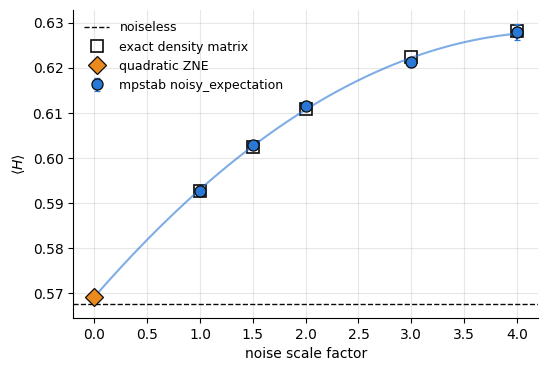

In [9]:
fig, ax = plt.subplots(figsize=(6, 4))
grid = np.linspace(0, factors.max(), 100)
ax.axhline(ideal, color="#0b0b0b", lw=1, ls="--", label="noiseless")
ax.plot(factors, exacts, "s", color="#0b0b0b", ms=8, mfc="none", mew=1.2, label="exact density matrix")
ax.errorbar(factors, values, yerr=errors, fmt="o", color="#2a78d6", ms=8, mec="#0b0b0b",
            mew=0.9, capsize=2, label="mpstab noisy_expectation")
ax.plot(grid, np.polyval(fit, grid), color="#2a78d6", lw=1.5, alpha=0.6)
ax.plot([0], [extrapolated], "D", color="#eb8a1c", ms=9, mec="#0b0b0b", mew=0.9, label="quadratic ZNE")
ax.set_xlabel("noise scale factor")
ax.set_ylabel(r"$\langle H \rangle$")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(alpha=0.3)
ax.legend(frameon=False, fontsize=9)
plt.show()

## Beyond density matrices

The cost of `noisy_expectation` is the number of sign patterns times the cost of a noiseless HSMPO evaluation, so it never touches a $4^n$ object. The same noise model runs unchanged on larger chains, where the bond-dimension cap `max_bond_dimension` controls the accuracy of each pattern; a 100-qubit density matrix would need $4^{100}$ entries.

Below we measure a local $Z_iZ_{i+1}$ in the middle of the chain. Only the rotations and faults inside its light cone can affect it, and `noisy_expectation` drops all the others exactly. After three steps that light cone covers a fixed number of qubits, so the value, the number of sign patterns and the cost barely depend on $n$: the value is the bulk value of an infinite chain. A global observable such as the full energy instead has a light cone growing with the chain, and its cost grows with $n$ (about 30 s at $n=24$ for the full $ZZ$ energy of this circuit).

In [10]:
for n in (16, 40, 100):
    big = ParametricKickedIsing(nqubits=n, n_steps=3, delta_h=0.2)
    middle = n // 2
    local = "".join("Z" if q in (middle, middle + 1) else "I" for q in range(n))
    surrogate = HSMPO(big, max_bond_dimension=32, progress=False)
    start = time.perf_counter()
    res = surrogate.noisy_expectation(local, noise, n_samples=500, seed=0)
    print(f"n={n:3d}: ideal {surrogate.expectation(local):+.4f}, "
          f"noisy {res.mean:+.4f} +- {res.stderr:.1e}, "
          f"{res.n_patterns} patterns, {time.perf_counter() - start:.1f} s")

n= 16: ideal +0.1123, noisy +0.1009 +- 1.8e-05, 384 patterns, 0.8 s


n= 40: ideal +0.1123, noisy +0.1009 +- 1.8e-05, 384 patterns, 1.5 s


n=100: ideal +0.1123, noisy +0.1009 +- 1.8e-05, 384 patterns, 3.7 s


## Summary

```python
noise = NoiseModel()
noise.add(DepolarizingError(1e-3))                 # after every gate
noise.add(PauliError({"ZZ": 5e-4}), gates.CNOT)    # correlated, on CNOTs
noise.add(CoherentError("ZZ", 0.02), gates.CNOT)   # residual coupling
noise.add(ReadoutError(0.01))                      # readout bit flips

ideal = hsmpo.expectation(obs)                     # float
noisy = hsmpo.noisy_expectation(obs, noise)        # .mean, .stderr
exact = noise.apply(circuit)                       # qibo density-matrix circuit
twice = noise.scaled(2.0)                          # noise-strength sweeps
```

Relaxation and other non-Pauli channels, crosstalk, idle noise and preparation errors: see the [device-level noise tutorial](advanced_noise.ipynb).